# Project 4 — Intelligent Document Classification

End-to-end NLP project: 20 Newsgroups → cleaning → TF-IDF → ML classification → evaluation → error analysis → saved model → SQLite → Streamlit.

In [1]:
print("Project 4: Intelligent Document Classification")
print("Starting the project...")

Project 4: Intelligent Document Classification
Starting the project...


In [2]:
# If needed, run once:
# !pip install pandas numpy matplotlib scikit-learn joblib streamlit

In [3]:
import re, sqlite3, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support

BASE = Path.cwd()
DATA_DIR = BASE / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODEL_DIR = BASE / "models"
for p in [DATA_DIR/"raw", PROCESSED_DIR, MODEL_DIR]:
    p.mkdir(parents=True, exist_ok=True)
print("Project folder:", BASE)

Project folder: /Users/rikeshtimalsina/Desktop/Project 4


## 1. Load the dataset

In [4]:
categories = ["comp.graphics", "rec.sport.baseball", "sci.med", "talk.politics.misc"]

train = fetch_20newsgroups(subset="train", categories=categories,
    remove=("headers","footers","quotes"), shuffle=True, random_state=42)
test = fetch_20newsgroups(subset="test", categories=categories,
    remove=("headers","footers","quotes"), shuffle=True, random_state=42)

df_train = pd.DataFrame({"text": train.data, "label_id": train.target,
                         "label": [train.target_names[i] for i in train.target]})
df_test = pd.DataFrame({"text": test.data, "label_id": test.target,
                        "label": [test.target_names[i] for i in test.target]})
print("Training:", df_train.shape)
print("Testing:", df_test.shape)
print("Categories:", train.target_names)

Training: (2240, 3)
Testing: (1492, 3)
Categories: ['comp.graphics', 'rec.sport.baseball', 'sci.med', 'talk.politics.misc']


## 2. Inspect the data

In [5]:
print("Missing text:", df_train.text.isna().sum())
print("Duplicate documents:", df_train.text.duplicated().sum())
print("\nClass distribution:")
print(df_train.label.value_counts())
df_train["word_count"] = df_train.text.str.split().str.len()
print("\nWord-count statistics:")
print(df_train.word_count.describe())

Missing text: 0
Duplicate documents: 57

Class distribution:
label
rec.sport.baseball    597
sci.med               594
comp.graphics         584
talk.politics.misc    465
Name: count, dtype: int64

Word-count statistics:
count    2240.000000
mean      185.440625
std       562.389458
min         0.000000
25%        38.000000
50%        75.500000
75%       157.000000
max      9109.000000
Name: word_count, dtype: float64


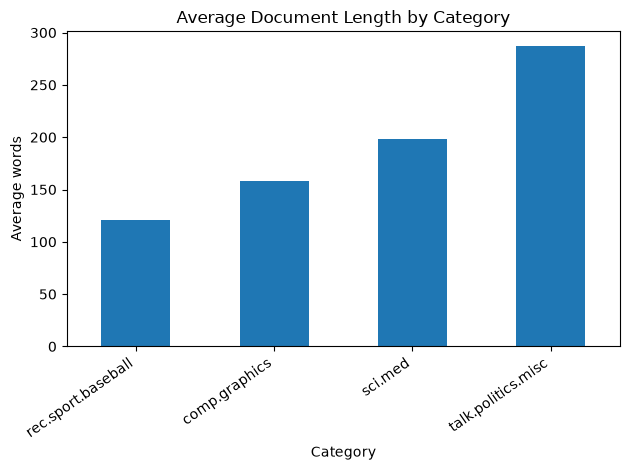

In [6]:
df_train.groupby("label").word_count.mean().sort_values().plot(kind="bar")
plt.title("Average Document Length by Category")
plt.xlabel("Category"); plt.ylabel("Average words")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

## 3. Clean the text

In [7]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df_train["clean_text"] = df_train.text.map(clean_text)
df_test["clean_text"] = df_test.text.map(clean_text)
df_train = df_train[df_train.clean_text.str.len() > 20].copy()
df_test = df_test[df_test.clean_text.str.len() > 20].copy()
print("Rows after cleaning:", len(df_train), len(df_test))

Rows after cleaning: 2152 1434


## 4. Logistic Regression baseline

In [8]:
X_train, y_train = df_train.clean_text, df_train.label
X_test, y_test = df_test.clean_text, df_test.label

logreg_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", min_df=2, max_df=0.95,
                              ngram_range=(1,2), sublinear_tf=True)),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])
logreg_pipeline.fit(X_train, y_train)
logreg_pred = logreg_pipeline.predict(X_test)
logreg_accuracy = accuracy_score(y_test, logreg_pred)
print(f"Logistic Regression accuracy: {logreg_accuracy:.4f}")
print(classification_report(y_test, logreg_pred, zero_division=0))

Logistic Regression accuracy: 0.8954
                    precision    recall  f1-score   support

     comp.graphics       0.90      0.93      0.91       382
rec.sport.baseball       0.92      0.93      0.92       373
           sci.med       0.88      0.89      0.88       378
talk.politics.misc       0.88      0.82      0.85       301

          accuracy                           0.90      1434
         macro avg       0.89      0.89      0.89      1434
      weighted avg       0.90      0.90      0.89      1434



## 5. Linear SVM

In [9]:
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", min_df=2, max_df=0.95,
                              ngram_range=(1,2), sublinear_tf=True)),
    ("model", LinearSVC(random_state=42))
])
svm_pipeline.fit(X_train, y_train)
svm_pred = svm_pipeline.predict(X_test)
svm_accuracy = accuracy_score(y_test, svm_pred)
print(f"Linear SVM accuracy: {svm_accuracy:.4f}")
print(classification_report(y_test, svm_pred, zero_division=0))

Linear SVM accuracy: 0.8989
                    precision    recall  f1-score   support

     comp.graphics       0.91      0.92      0.92       382
rec.sport.baseball       0.91      0.93      0.92       373
           sci.med       0.90      0.89      0.90       378
talk.politics.misc       0.86      0.84      0.85       301

          accuracy                           0.90      1434
         macro avg       0.90      0.90      0.90      1434
      weighted avg       0.90      0.90      0.90      1434



## 6. Compare models

,Model,Accuracy
0,Logistic Regression,0.895397
1,Linear SVM,0.898884


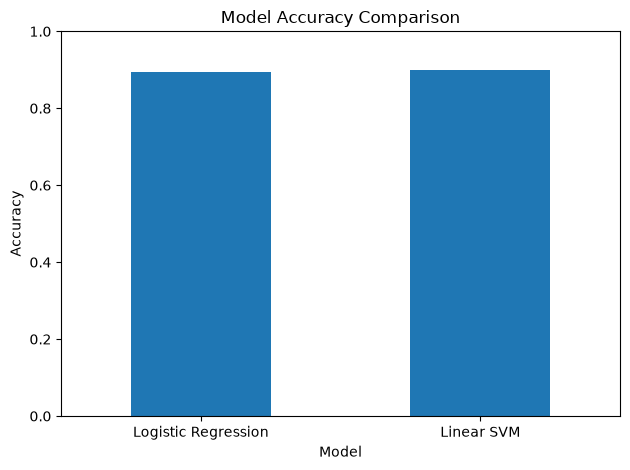

In [10]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM"],
    "Accuracy": [logreg_accuracy, svm_accuracy]
})
display(comparison)
comparison.plot(x="Model", y="Accuracy", kind="bar", legend=False, ylim=(0,1),
                title="Model Accuracy Comparison")
plt.ylabel("Accuracy"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 7. Confusion matrix

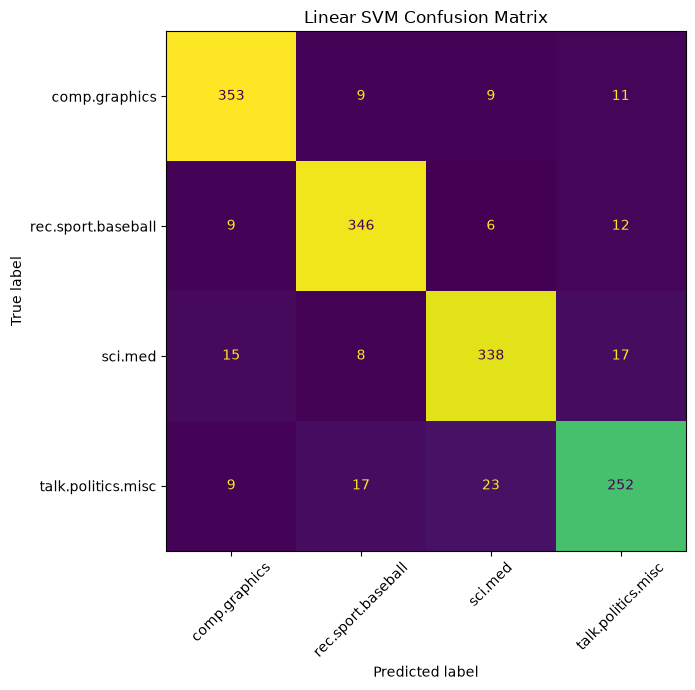

,category,precision,recall,f1,support
0,comp.graphics,0.914508,0.924084,0.919271,382
1,rec.sport.baseball,0.910526,0.927614,0.918991,373
2,sci.med,0.898936,0.894180,0.896552,378
3,talk.politics.misc,0.863014,0.837209,0.849916,301


In [11]:
final_model = svm_pipeline
final_pred = svm_pred
cm = confusion_matrix(y_test, final_pred, labels=final_model.classes_)
fig, ax = plt.subplots(figsize=(9,7))
ConfusionMatrixDisplay(cm, display_labels=final_model.classes_).plot(
    ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Linear SVM Confusion Matrix"); plt.tight_layout(); plt.show()

precision, recall, f1, support = precision_recall_fscore_support(
    y_test, final_pred, labels=final_model.classes_, zero_division=0)
metrics_df = pd.DataFrame({"category":final_model.classes_, "precision":precision,
                           "recall":recall, "f1":f1, "support":support})
display(metrics_df)

## 8. Error analysis

In [12]:
error_df = pd.DataFrame({"text": X_test.values, "actual": y_test.values,
                                "predicted": final_pred})
errors = error_df[error_df.actual != error_df.predicted].copy()
print("Incorrect predictions:", len(errors))
print("Error rate:", len(errors)/len(error_df))
display(errors.head(10))

Incorrect predictions: 145
Error rate: 0.10111576011157601


,text,actual,predicted
18,did your ent also tell you that this procedure...,sci.med,talk.politics.misc
26,furthermore in response to an earlier message ...,talk.politics.misc,sci.med
49,i have successfully copied all of the uuencode...,rec.sport.baseball,comp.graphics
65,less than people or more,rec.sport.baseball,talk.politics.misc
84,lucas film pixar d eye inc light magic,comp.graphics,sci.med
87,cute anecdote but hardly indicative of the pop...,sci.med,talk.politics.misc
110,heheheheh sorry roger i wronged you you re not...,rec.sport.baseball,talk.politics.misc
126,which number is that zero please present a num...,talk.politics.misc,sci.med
131,i think it s known but it s neat can it be ext...,comp.graphics,rec.sport.baseball
133,cardinals for poor without opening this up for...,rec.sport.baseball,sci.med


## 9. Save model

In [13]:
model_path = MODEL_DIR / "document_classifier.joblib"
joblib.dump(final_model, model_path)
print("Saved:", model_path)

Saved: /Users/rikeshtimalsina/Desktop/Project 4/models/document_classifier.joblib


## 10. Test saved model

In [14]:
loaded_model = joblib.load(model_path)
samples = [
    "The baseball team won the game after a strong pitching performance.",
    "The graphics card renders high resolution images and advanced video.",
    "The doctor discussed treatment options and the patient's medical condition.",
    "The government announced a new policy after a political debate."
]
for text, pred in zip(samples, loaded_model.predict(samples)):
    print("TEXT:", text)
    print("PREDICTED:", pred)
    print("-"*70)

TEXT: The baseball team won the game after a strong pitching performance.
PREDICTED: rec.sport.baseball
----------------------------------------------------------------------
TEXT: The graphics card renders high resolution images and advanced video.
PREDICTED: comp.graphics
----------------------------------------------------------------------
TEXT: The doctor discussed treatment options and the patient's medical condition.
PREDICTED: sci.med
----------------------------------------------------------------------
TEXT: The government announced a new policy after a political debate.
PREDICTED: talk.politics.misc
----------------------------------------------------------------------


## 11. Save processed data

In [15]:
df_train[["text","clean_text","label"]].to_csv(PROCESSED_DIR/"train_clean.csv", index=False)
df_test[["text","clean_text","label"]].to_csv(PROCESSED_DIR/"test_clean.csv", index=False)
print("Processed CSV files saved.")

Processed CSV files saved.


## 12. SQLite analytics

In [16]:
DB_PATH = BASE / "document_classification.db"
results_df = pd.DataFrame({
    "text": X_test.values, "actual_label": y_test.values,
    "predicted_label": final_pred, "correct": (y_test.values == final_pred)
})
conn = sqlite3.connect(DB_PATH)
results_df.to_sql("predictions", conn, if_exists="replace", index=False)
conn.commit()

summary = pd.read_sql_query(
    "SELECT COUNT(*) total_predictions, SUM(correct) correct_predictions, AVG(correct) accuracy FROM predictions", conn)
by_class = pd.read_sql_query(
    "SELECT actual_label, COUNT(*) total, SUM(correct) correct, AVG(correct) accuracy "
    "FROM predictions GROUP BY actual_label ORDER BY total DESC", conn)
conn.close()
display(summary); display(by_class)
print("Database:", DB_PATH)

,total_predictions,correct_predictions,accuracy
0,1434,1289,0.898884


,actual_label,total,correct,accuracy
0,comp.graphics,382,353,0.924084
1,sci.med,378,338,0.894180
2,rec.sport.baseball,373,346,0.927614
3,talk.politics.misc,301,252,0.837209


Database: /Users/rikeshtimalsina/Desktop/Project 4/document_classification.db


## 13. Final summary

In [17]:
print("PROJECT 4 COMPLETE")
print("="*50)
print("Training documents:", len(df_train))
print("Testing documents:", len(df_test))
print(f"Logistic Regression accuracy: {logreg_accuracy:.4f}")
print(f"Linear SVM accuracy: {svm_accuracy:.4f}")
print("Final model: TF-IDF + Linear SVM")
print("Model:", model_path)
print("Database:", DB_PATH)
print("="*50)

PROJECT 4 COMPLETE
Training documents: 2152
Testing documents: 1434
Logistic Regression accuracy: 0.8954
Linear SVM accuracy: 0.8989
Final model: TF-IDF + Linear SVM
Model: /Users/rikeshtimalsina/Desktop/Project 4/models/document_classifier.joblib
Database: /Users/rikeshtimalsina/Desktop/Project 4/document_classification.db
